In [4]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Liberation Serif", "DejaVu Serif"],
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
    "text.color": "black",
    "axes.labelcolor": "black",
    "axes.edgecolor": "black",
    "xtick.color": "black",
    "ytick.color": "black",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "font.size": 11,
})

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

matches = pd.read_csv("matches.csv")
results = pd.read_csv("results.csv")
rankings = pd.read_csv("ranking_fifa_historical.csv")
elo = pd.read_csv("elo_ratings_wc2026.csv")

print("Matches:", matches.shape)
print("Historical results:", results.shape)
print("FIFA rankings:", rankings.shape)
print("Elo ratings:", elo.shape)

Matches: (104, 42)
Historical results: (49945, 9)
FIFA rankings: (67894, 6)
Elo ratings: (4683, 23)


In [4]:

matches["date"] = pd.to_datetime(
    matches["date"], dayfirst=True, errors="coerce"
)
results["date"] = pd.to_datetime(
    results["date"], errors="coerce"
)
rankings["date"] = pd.to_datetime(
    rankings["date"], errors="coerce"
)
elo["snapshot_date"] = pd.to_datetime(
    elo["snapshot_date"], errors="coerce"
)

results_names = {
    "Bosnia and Herzegovina": "Bosnia–Herz",
    "Cape Verde": "Cabo Verde",
    "DR Congo": "Congo DR",
    "Czech Republic": "Czechia",
    "Ivory Coast": "Côte d'Ivoire",
    "Iran": "IR Iran",
    "South Korea": "Korea Republic",
    "Turkey": "Türkiye"
}

for col in ["home_team", "away_team"]:
    results[col] = results[col].replace(results_names)

rankings["team"] = rankings["team"].replace({
    "Bosnia and Herzegovina": "Bosnia–Herz",
    "USA": "United States",
    "Turkey": "Türkiye",
    "Aotearoa New Zealand": "New Zealand"
})

elo["country"] = elo["country"].replace({
    "Bosnia and Herzegovina": "Bosnia–Herz",
    "Cape Verde": "Cabo Verde",
    "DR Congo": "Congo DR",
    "Ivory Coast": "Côte d'Ivoire",
    "Iran": "IR Iran",
    "South Korea": "Korea Republic",
    "Turkey": "Türkiye"
})

results = results[
    ["date", "home_team", "away_team", "home_score", "away_score"]
].copy()

results["home_score"] = pd.to_numeric(
    results["home_score"], errors="coerce"
)
results["away_score"] = pd.to_numeric(
    results["away_score"], errors="coerce"
)

results = results.dropna(
    subset=["date", "home_team", "away_team", "home_score", "away_score"]
)

results = results.sort_values("date").reset_index(drop=True)

print("Historical results prepared:", results.shape)

Historical results prepared: (49945, 5)


In [5]:

def get_recent_stats(team, match_date, results, n=5):
    past = results[
        (results["date"] < match_date) &
        (
            (results["home_team"] == team) |
            (results["away_team"] == team)
        )
    ].sort_values("date", ascending=False).head(n)

    if len(past) < n:
        return np.nan, np.nan, np.nan

    wins = 0
    goals_scored = []
    goals_conceded = []

    for _, row in past.iterrows():
        if row["home_team"] == team:
            goals_for = row["home_score"]
            goals_against = row["away_score"]
        else:
            goals_for = row["away_score"]
            goals_against = row["home_score"]

        goals_scored.append(goals_for)
        goals_conceded.append(goals_against)

        if goals_for > goals_against:
            wins += 1

    win_pct = wins / n
    avg_scored = np.mean(goals_scored)
    avg_conceded = np.mean(goals_conceded)

    return win_pct, avg_scored, avg_conceded


def get_rest_days(team, match_date, results):
    past = results[
        (results["date"] < match_date) &
        (
            (results["home_team"] == team) |
            (results["away_team"] == team)
        )
    ].sort_values("date", ascending=False)

    if past.empty:
        return np.nan

    return (match_date - past.iloc[0]["date"]).days

In [6]:

elo_pre_wc = elo[
    elo["snapshot_date"] == pd.Timestamp("2026-05-27")
].copy()

elo_rating_map = dict(
    zip(elo_pre_wc["country"], elo_pre_wc["rating"])
)

matches["home_elo"] = matches["home_team"].map(elo_rating_map)
matches["away_elo"] = matches["away_team"].map(elo_rating_map)

print("Missing home Elo:", matches["home_elo"].isna().sum())
print("Missing away Elo:", matches["away_elo"].isna().sum())

Missing home Elo: 0
Missing away Elo: 0


In [7]:

rows = []

for match_id, match in matches.iterrows():
    home_stats = get_recent_stats(
        match["home_team"], match["date"], results
    )
    away_stats = get_recent_stats(
        match["away_team"], match["date"], results
    )

    home_rest = get_rest_days(
        match["home_team"], match["date"], results
    )
    away_rest = get_rest_days(
        match["away_team"], match["date"], results
    )

    # Home team row
    rows.append({
        "match_id": match_id,
        "team": match["home_team"],
        "team_elo": match["home_elo"],
        "opponent_elo": match["away_elo"],
        "team_win_pct_5": home_stats[0],
        "opponent_win_pct_5": away_stats[0],
        "team_avg_conceded_5": home_stats[2],
        "opponent_avg_conceded_5": away_stats[2],
        "team_rest_days": home_rest,
        "opponent_rest_days": away_rest,
        "team_goals": match["home_score"]
    })

    # Away team row
    rows.append({
        "match_id": match_id,
        "team": match["away_team"],
        "team_elo": match["away_elo"],
        "opponent_elo": match["home_elo"],
        "team_win_pct_5": away_stats[0],
        "opponent_win_pct_5": home_stats[0],
        "team_avg_conceded_5": away_stats[2],
        "opponent_avg_conceded_5": home_stats[2],
        "team_rest_days": away_rest,
        "opponent_rest_days": home_rest,
        "team_goals": match["away_score"]
    })

team_matches = pd.DataFrame(rows)

print("Dataset shape:", team_matches.shape)
print("Unique matches:", team_matches["match_id"].nunique())
print("\nMissing values:")
print(team_matches.isna().sum())

Dataset shape: (208, 11)
Unique matches: 104

Missing values:
match_id                   0
team                       0
team_elo                   0
opponent_elo               0
team_win_pct_5             0
opponent_win_pct_5         0
team_avg_conceded_5        0
opponent_avg_conceded_5    0
team_rest_days             0
opponent_rest_days         0
team_goals                 0
dtype: int64


In [8]:

features_22 = [
    "team_elo",
    "opponent_elo",
    "team_win_pct_5",
    "opponent_win_pct_5",
    "team_avg_conceded_5",
    "opponent_avg_conceded_5",
    "team_rest_days",
    "opponent_rest_days"
]

X22 = team_matches[features_22]
y22 = team_matches["team_goals"]

print("X shape:", X22.shape)
print("y shape:", y22.shape)

X shape: (208, 8)
y shape: (208,)


In [9]:

cv = GroupKFold(n_splits=5)
groups = team_matches["match_id"]

model22 = LinearRegression()

predictions = cross_val_predict(
    model22, X22, y22,
    cv=cv,
    groups=groups
)

print("Linear Regression Results")
print("R²:", round(r2_score(y22, predictions), 3))
print("MAE:", round(mean_absolute_error(y22, predictions), 3))
print("RMSE:", round(np.sqrt(mean_squared_error(y22, predictions)), 3))

Linear Regression Results
R²: -0.619
MAE: 1.062
RMSE: 1.769


In [10]:

baseline = DummyRegressor(strategy="mean")

baseline_predictions = cross_val_predict(
    baseline, X22, y22,
    cv=cv,
    groups=groups
)

print("Baseline Results")
print("R²:", round(r2_score(y22, baseline_predictions), 3))
print("MAE:", round(mean_absolute_error(y22, baseline_predictions), 3))
print("RMSE:", round(np.sqrt(mean_squared_error(y22, baseline_predictions)), 3))

Baseline Results
R²: -0.005
MAE: 1.114
RMSE: 1.394


In [11]:

print("Target distribution:")
print(team_matches["team_goals"].describe())

print("\nFeature correlations with team_goals:")
print(
    team_matches[features_22 + ["team_goals"]]
    .corr(numeric_only=True)["team_goals"]
    .sort_values()
)

print("\nMissing values:")
print(team_matches[features_22 + ["team_goals"]].isna().sum())

Target distribution:
count    208.000000
mean       1.480769
std        1.393434
min        0.000000
25%        0.000000
50%        1.000000
75%        2.000000
max        7.000000
Name: team_goals, dtype: float64

Feature correlations with team_goals:
opponent_elo              -0.328686
opponent_win_pct_5        -0.263937
team_avg_conceded_5       -0.151812
opponent_rest_days        -0.037711
team_rest_days            -0.012956
team_win_pct_5             0.205901
opponent_avg_conceded_5    0.249371
team_elo                   0.344354
team_goals                 1.000000
Name: team_goals, dtype: float64

Missing values:
team_elo                   0
opponent_elo               0
team_win_pct_5             0
opponent_win_pct_5         0
team_avg_conceded_5        0
opponent_avg_conceded_5    0
team_rest_days             0
opponent_rest_days         0
team_goals                 0
dtype: int64


In [12]:
comparison = pd.DataFrame({
    "actual_goals": y22,
    "predicted_goals": predictions
})

print(comparison.head(15).round(2))
print("\nActual mean:", round(y22.mean(), 3))
print("Predicted mean:", round(predictions.mean(), 3))

    actual_goals  predicted_goals
0              2             2.18
1              0             0.42
2              2             1.44
3              1             1.31
4              1             1.82
5              1             0.73
6              4             1.18
7              1             2.03
8              1             0.37
9              1             2.73
10             1             1.78
11             1             1.18
12             2             1.01
13             0             1.82
14             0             0.73

Actual mean: 1.481
Predicted mean: 1.475


In [13]:

features_simple = [
    "team_elo",
    "opponent_elo",
    "opponent_win_pct_5",
    "opponent_avg_conceded_5"
]

X_simple = team_matches[features_simple]

simple_predictions = cross_val_predict(
    LinearRegression(),
    X_simple,
    y22,
    cv=cv,
    groups=groups
)

print("Simpler Linear Regression")
print("R²:", round(r2_score(y22, simple_predictions), 3))
print("MAE:", round(mean_absolute_error(y22, simple_predictions), 3))
print("RMSE:", round(np.sqrt(mean_squared_error(y22, simple_predictions)), 3))

Simpler Linear Regression
R²: 0.216
MAE: 0.928
RMSE: 1.231


In [14]:

def get_recent_stats(team, match_date, results, n=5):
    past = results[
        (results["date"] < match_date) &
        (
            (results["home_team"] == team) |
            (results["away_team"] == team)
        )
    ].sort_values("date", ascending=False).head(n)

    if len(past) < n:
        return np.nan, np.nan, np.nan

    goals_scored = []
    goals_conceded = []
    wins = 0

    for _, row in past.iterrows():
        if row["home_team"] == team:
            gf, ga = row["home_score"], row["away_score"]
        else:
            gf, ga = row["away_score"], row["home_score"]

        goals_scored.append(gf)
        goals_conceded.append(ga)
        if gf > ga:
            wins += 1

    return wins / n, np.mean(goals_scored), np.mean(goals_conceded)

In [15]:

rows = []

for match_id, match in matches.iterrows():
    home_stats = get_recent_stats(
        match["home_team"], match["date"], results
    )
    away_stats = get_recent_stats(
        match["away_team"], match["date"], results
    )

    home_rest = get_rest_days(
        match["home_team"], match["date"], results
    )
    away_rest = get_rest_days(
        match["away_team"], match["date"], results
    )

    # Home team
    rows.append({
        "match_id": match_id,
        "team": match["home_team"],
        "team_elo": match["home_elo"],
        "opponent_elo": match["away_elo"],
        "team_win_pct_5": home_stats[0],
        "opponent_win_pct_5": away_stats[0],
        "team_avg_scored_5": home_stats[1],
        "opponent_avg_scored_5": away_stats[1],
        "team_avg_conceded_5": home_stats[2],
        "opponent_avg_conceded_5": away_stats[2],
        "team_goals": match["home_score"]
    })

    # Away team
    rows.append({
        "match_id": match_id,
        "team": match["away_team"],
        "team_elo": match["away_elo"],
        "opponent_elo": match["home_elo"],
        "team_win_pct_5": away_stats[0],
        "opponent_win_pct_5": home_stats[0],
        "team_avg_scored_5": away_stats[1],
        "opponent_avg_scored_5": home_stats[1],
        "team_avg_conceded_5": away_stats[2],
        "opponent_avg_conceded_5": home_stats[2],
        "team_goals": match["away_score"]
    })

team_matches = pd.DataFrame(rows)

print("Dataset shape:", team_matches.shape)
print("Missing values:")
print(team_matches.isna().sum())

Dataset shape: (208, 11)
Missing values:
match_id                   0
team                       0
team_elo                   0
opponent_elo               0
team_win_pct_5             0
opponent_win_pct_5         0
team_avg_scored_5          0
opponent_avg_scored_5      0
team_avg_conceded_5        0
opponent_avg_conceded_5    0
team_goals                 0
dtype: int64


In [16]:

features_22 = [
    "team_elo",
    "opponent_elo",
    "team_win_pct_5",
    "opponent_win_pct_5",
    "team_avg_scored_5",
    "opponent_avg_scored_5",
    "team_avg_conceded_5",
    "opponent_avg_conceded_5"
]

X22 = team_matches[features_22]
y22 = team_matches["team_goals"]

print("X shape:", X22.shape)
print("y shape:", y22.shape)

X shape: (208, 8)
y shape: (208,)


In [17]:

cv = GroupKFold(n_splits=5)
groups = team_matches["match_id"]

model22 = LinearRegression()

predictions = cross_val_predict(
    model22,
    X22,
    y22,
    cv=cv,
    groups=groups
)

print("Linear Regression Results")
print("R²:", round(r2_score(y22, predictions), 3))
print("MAE:", round(mean_absolute_error(y22, predictions), 3))
print("RMSE:", round(np.sqrt(mean_squared_error(y22, predictions)), 3))

Linear Regression Results
R²: 0.188
MAE: 0.946
RMSE: 1.252


In [18]:

baseline = DummyRegressor(strategy="mean")

baseline_predictions = cross_val_predict(
    baseline,
    X22,
    y22,
    cv=cv,
    groups=groups
)

print("Baseline Results")
print("R²:", round(r2_score(y22, baseline_predictions), 3))
print("MAE:", round(mean_absolute_error(y22, baseline_predictions), 3))
print("RMSE:", round(np.sqrt(mean_squared_error(y22, baseline_predictions)), 3))

Baseline Results
R²: -0.005
MAE: 1.114
RMSE: 1.394


In [19]:

# Fit the final model on all 208 rows
final_model22 = LinearRegression()
final_model22.fit(X22, y22)

# Save the dataset and model
team_matches.to_csv("linear_regression_2_2_dataset.csv", index=False)

import joblib
joblib.dump(final_model22, "linear_regression_2_2_model.pkl")

print("Final model and dataset saved.")
print("Rows:", len(team_matches))
print("Explanatory variables:", len(features_22))
print("Predictors:", features_22)

Final model and dataset saved.
Rows: 208
Explanatory variables: 8
Predictors: ['team_elo', 'opponent_elo', 'team_win_pct_5', 'opponent_win_pct_5', 'team_avg_scored_5', 'opponent_avg_scored_5', 'team_avg_conceded_5', 'opponent_avg_conceded_5']


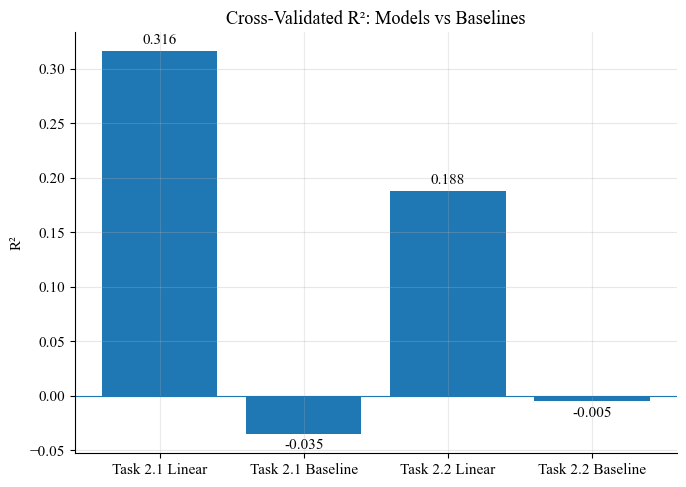

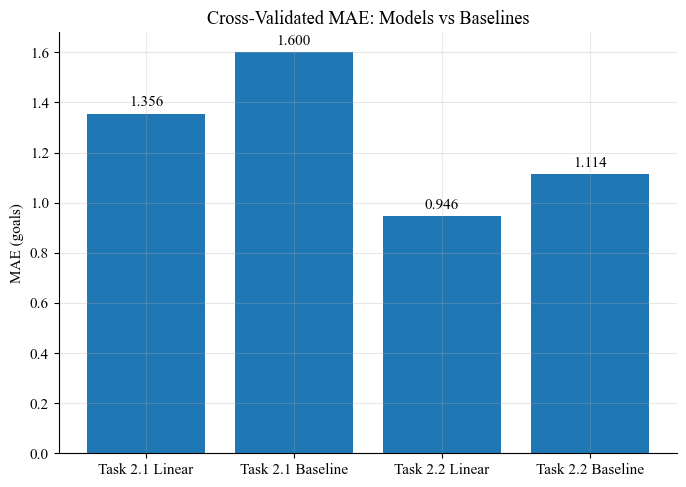

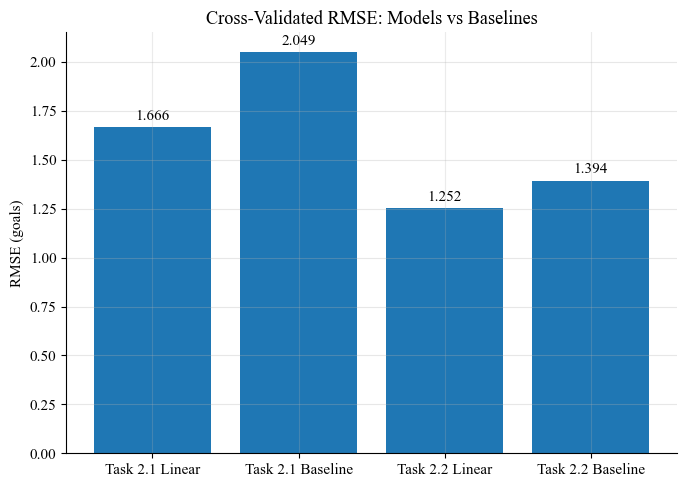

In [5]:
labels = ["Task 2.1 Linear", "Task 2.1 Baseline",
          "Task 2.2 Linear", "Task 2.2 Baseline"]

def plot_metric(values, title, ylabel, zero_line=False):
    fig, ax = plt.subplots(figsize=(7, 5))
    bars = ax.bar(labels, values)
    if zero_line:
        ax.axhline(0, linewidth=0.8)
    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.bar_label(bars, fmt="%.3f", padding=3)
    ax.grid(axis="y", alpha=0.3)
    fig.tight_layout()
    plt.show()

plot_metric([0.316, -0.035, 0.188, -0.005],
            "Cross-Validated R²: Models vs Baselines", "R²", True)
plot_metric([1.356, 1.600, 0.946, 1.114],
            "Cross-Validated MAE: Models vs Baselines", "MAE (goals)")
plot_metric([1.666, 2.049, 1.252, 1.394],
            "Cross-Validated RMSE: Models vs Baselines", "RMSE (goals)")
